# Dataset Description
## Kilogrammes of CO2-equivalent per person

**Source**: [OECD](https://data-explorer.oecd.org/vis?fs[0]=Topic,1%7CEnvironment%20and%20climate%20change%23ENV%23%7CAir%20and%20climate%23ENV_AC%23&pg=0&fc=Topic&bp=true&snb=16&vw=tb&df[ds]=dsDisseminateFinalDMZ&df[id]=DSD_AIR_GHG%40DF_AIR_GHG&df[ag]=OECD.ENV.EPI&df[vs]=1.0&dq=MEX%2BCRI%2BCHL%2BARG%2BBRA%2BCUB%2BPER%2BVEN%2BURY%2BGTM%2BPAN%2BCOL.A.GHG._T.KG_CO2E_PS&pd=1988,2021&to[TIME_PERIOD]=false)

# Code
## Imports

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

## Load data

In [5]:
path = "./data/pollution.csv"

df = pd.read_csv(
    path, encoding="utf-8",
    usecols=[1,6, 7],
    header=0,
    names=["country", "year", "value"]
)

## Clean data

In [6]:
df["real_value"] = df["value"] * 1000
wide = df.pivot(index="year", columns="country", values="real_value").sort_index()

## plot

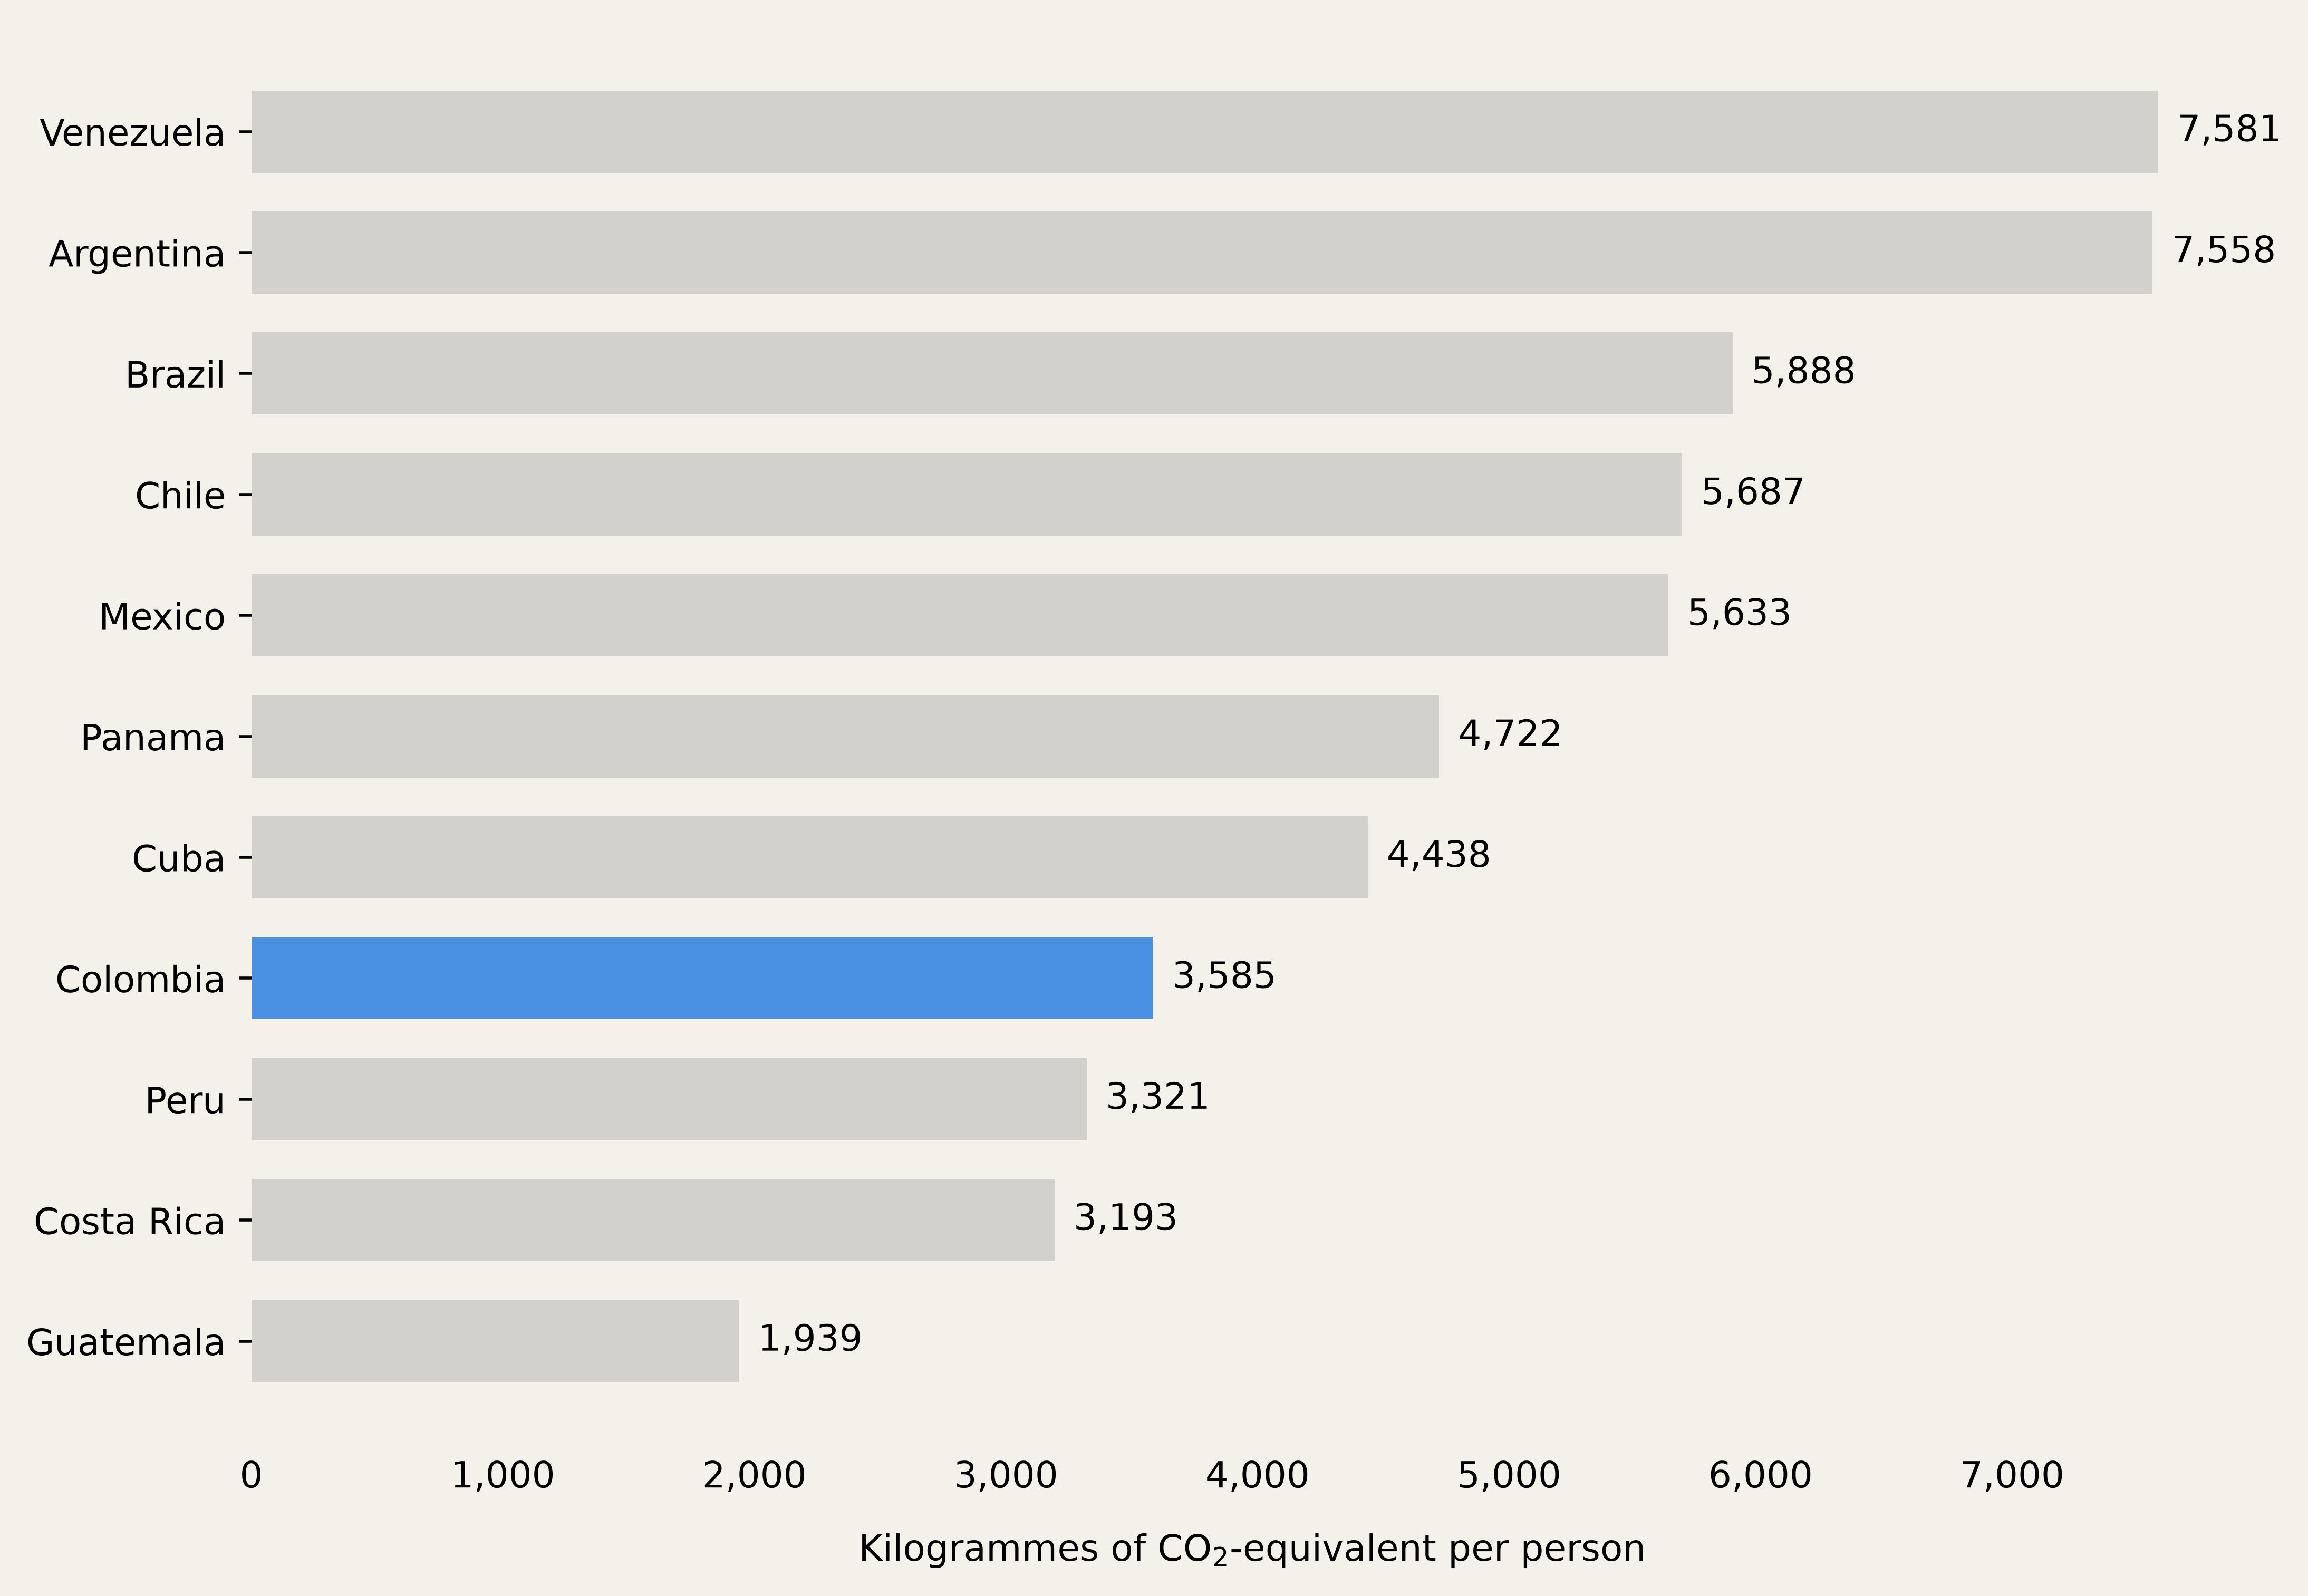

In [8]:
background = "#F4F1EA"
colombia = "#4a90e2"

def ranked_bar(df, year=2021, highlight="Colombia", col="real_value"):
    d = df[df.year == year].sort_values(col, ascending=True)
    colors = [colombia if c == highlight else "#d3d1cc" for c in d.country]

    plt.figure(figsize=(9.8, 7.0), dpi=500, facecolor=background)
    plt.gca().set_facecolor(background)

    bars = plt.barh(d.country, d[col], color=colors, height=0.68)
    offset = d[col].max() * 0.01
    for b, v in zip(bars, d[col]):
        plt.text(v + offset, b.get_y() + b.get_height() / 2, f"{v:,.0f}", va="center")

    plt.xlabel("Kilogrammes of CO$_2$-equivalent per person, per year", labelpad=10, fontsize=10)

    plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

    for s in ("top", "right", "left", "bottom"):
        plt.gca().spines[s].set_visible(False)

    plt.tick_params(axis="x", length=0)

ranked_bar(df, 2021)
plt.show()